<a href="https://colab.research.google.com/github/Vyachick228/pattern-recognition-practice/blob/main/notebooks/PR03_Shapovalov_Vladyslav.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Практична робота 3

## Перша модель і базове оцінювання якості

**Дисципліна:** Розпізнавання образів та класичне машинне навчання

**Студент:** Шаповалов Владислав

**Група:** ІН-32/2

**Дата виконання:** 05.11.2026

### Мета роботи

Побудувати першу завершену модель машинного навчання, отримати прогнози та навчитися оцінювати їхню якість за допомогою основних метрик класифікації.


# 1. Підключення бібліотек

Підключаються бібліотеки для аналізу даних, побудови моделей та оцінювання їхньої якості.


In [1]:
from pathlib import Path
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay
)
from IPython.display import display


# 2. Підключення Google Drive
Використовується спільний проєкт із практичних робіт №1 і №2.

In [2]:
drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/pattern-recognition-practice')
DATA_PATH = PROJECT_DIR / 'data' / 'processed' / 'iris_cleaned.csv'
MODELS_DIR = PROJECT_DIR / 'models'
REPORTS_DIR = PROJECT_DIR / 'reports'
MODEL_PATH = MODELS_DIR / 'iris_decision_tree.joblib'
METRICS_PATH = REPORTS_DIR / 'model_metrics.csv'
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
print('Файл даних:', DATA_PATH)
print('Файл моделі:', MODEL_PATH)


Mounted at /content/drive
Файл даних: /content/drive/MyDrive/pattern-recognition-practice/data/processed/iris_cleaned.csv
Файл моделі: /content/drive/MyDrive/pattern-recognition-practice/models/iris_decision_tree.joblib


# 3. Завантаження підготовленого набору даних
Зчитуємо очищений набір iris_cleaned.csv із попередньої практичної роботи.

In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError('Файл iris_cleaned.csv не знайдено. Перевірте практичну роботу 2.')
data = pd.read_csv(DATA_PATH)
display(data.head())
print('Розмір таблиці:', data.shape)
print('Типи даних:')
print(data.dtypes)
print('Кількість пропусків:', int(data.isna().sum().sum()))


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
0,5.1,3.5,1.4,0.2,setosa,device_c
1,5.8,3.0,1.4,0.2,setosa,device_b
2,4.7,3.2,1.3,0.2,setosa,device_c
3,5.1,3.1,1.5,0.2,setosa,device_b
4,5.0,3.6,1.4,0.2,setosa,device_a


Розмір таблиці: (148, 6)
Типи даних:
sepal_length_cm       float64
sepal_width_cm        float64
petal_length_cm       float64
petal_width_cm        float64
species                object
measurement_device     object
dtype: object
Кількість пропусків: 0


# 4. Формування ознак і цільової змінної
species є правильною відповіддю і не повинна входити до X, щоб уникнути витоку даних. Категоріальні ознаки кодуємо методом one-hot.

In [4]:
X = data.drop(columns=['species'])
y = data['species']
categorical_columns = X.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
print('Категоріальні ознаки:', categorical_columns)
X = pd.get_dummies(X, columns=categorical_columns, dtype=int)
print('Розмір X:', X.shape)
print('Розмір y:', y.shape)
display(X.head())


Категоріальні ознаки: ['measurement_device']
Розмір X: (148, 7)
Розмір y: (148,)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,measurement_device_device_a,measurement_device_device_b,measurement_device_device_c
0,5.1,3.5,1.4,0.2,0,0,1
1,5.8,3.0,1.4,0.2,0,1,0
2,4.7,3.2,1.3,0.2,0,0,1
3,5.1,3.1,1.5,0.2,0,1,0
4,5.0,3.6,1.4,0.2,1,0,0


# 5. Навчальна й тестова вибірки
Виділяємо 20 % даних для тестування. random_state=42 забезпечує відтворюваність, а stratify=y зберігає частки класів.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)
split_distribution = pd.DataFrame({
    'train_percent': y_train.value_counts(normalize=True).sort_index().mul(100).round(2),
    'test_percent': y_test.value_counts(normalize=True).sort_index().mul(100).round(2)
})
display(split_distribution)


X_train: (118, 7)
X_test: (30, 7)
y_train: (118,)
y_test: (30,)


,train_percent,test_percent
species,,
setosa,33.90,33.33
versicolor,33.05,33.33
virginica,33.05,33.33


# 6. Базова модель DummyClassifier
Базова модель прогнозує найчастіший клас. Її результат слугує орієнтиром для порівняння.

In [6]:
dummy_model = DummyClassifier(strategy='most_frequent')
dummy_model.fit(X_train, y_train)
dummy_train_predictions = dummy_model.predict(X_train)
dummy_test_predictions = dummy_model.predict(X_test)
print('DummyClassifier завжди прогнозує:', dummy_model.classes_[dummy_model.class_prior_.argmax()])
display(pd.DataFrame({
    'actual': y_test.iloc[:10].values,
    'predicted': dummy_test_predictions[:10]
}))


DummyClassifier завжди прогнозує: setosa


,actual,predicted
0,versicolor,setosa
1,versicolor,setosa
2,virginica,setosa
3,setosa,setosa
4,virginica,setosa
5,versicolor,setosa
6,versicolor,setosa
7,setosa,setosa
8,virginica,setosa
9,virginica,setosa


# 7. Дерево рішень
Навчаємо модель DecisionTreeClassifier(max_depth=3, random_state=42).

In [7]:
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X_train, y_train)
tree_train_predictions = tree_model.predict(X_train)
tree_test_predictions = tree_model.predict(X_test)
prediction_preview = pd.DataFrame({
    'actual': y_test.iloc[:15].values,
    'predicted': tree_test_predictions[:15]
})
prediction_preview['correct'] = prediction_preview['actual'] == prediction_preview['predicted']
display(prediction_preview)
print('Правильних серед перших 15:', int(prediction_preview['correct'].sum()))


,actual,predicted,correct
0,versicolor,versicolor,True
1,versicolor,versicolor,True
2,virginica,virginica,True
3,setosa,setosa,True
4,virginica,virginica,True
5,versicolor,versicolor,True
6,versicolor,versicolor,True
7,setosa,setosa,True
8,virginica,virginica,True
9,virginica,virginica,True


Правильних серед перших 15: 15


# 8. Оцінювання якості моделей
Обчислюємо accuracy, precision, recall і F1-macro для train і test та порівнюємо моделі.

,model,dataset,accuracy,precision_macro,recall_macro,f1_macro
0,DummyClassifier,train,0.339,0.113,0.333,0.169
1,DummyClassifier,test,0.333,0.111,0.333,0.167
2,DecisionTree,train,0.983,0.984,0.983,0.983
3,DecisionTree,test,0.933,0.936,0.933,0.933


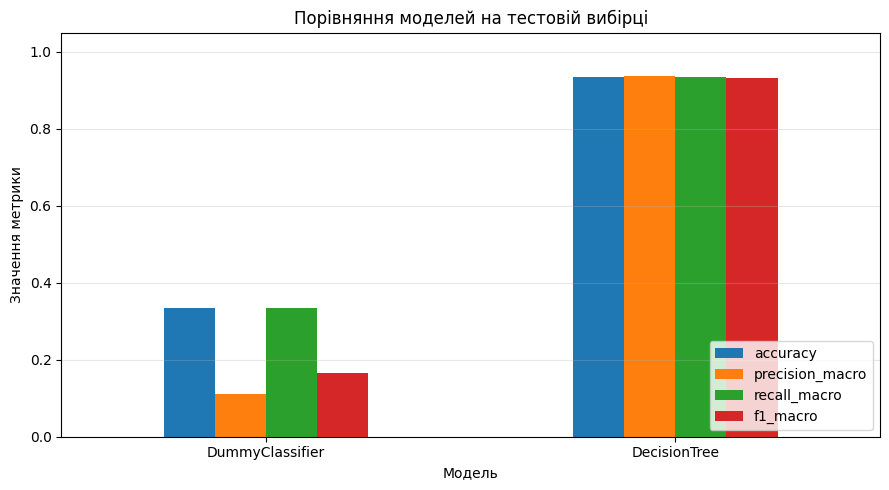

In [8]:
# Макроусереднення надає всім трьом класам однакову вагу.
def calculate_metrics(model_name, dataset_name, y_true, y_pred):
    return {
        'model': model_name,
        'dataset': dataset_name,
        'accuracy': accuracy_score(y_true, y_pred),
        'precision_macro': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'recall_macro': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0)
    }

metrics_df = pd.DataFrame([
    calculate_metrics('DummyClassifier', 'train', y_train, dummy_train_predictions),
    calculate_metrics('DummyClassifier', 'test', y_test, dummy_test_predictions),
    calculate_metrics('DecisionTree', 'train', y_train, tree_train_predictions),
    calculate_metrics('DecisionTree', 'test', y_test, tree_test_predictions)
])
display(metrics_df.round(3))

test_metrics = metrics_df[metrics_df['dataset'] == 'test'].set_index('model')
test_metrics[['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']].plot(
    kind='bar', figsize=(9, 5)
)
plt.title('Порівняння моделей на тестовій вибірці')
plt.xlabel('Модель')
plt.ylabel('Значення метрики')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


# 9. Порівняння train і test
Великий розрив між train і test може свідчити про перенавчання.

In [9]:
train_test_comparison = metrics_df.pivot(
    index='model', columns='dataset', values=['accuracy', 'f1_macro']
)
display(train_test_comparison.round(3))
tree_train_accuracy = accuracy_score(y_train, tree_train_predictions)
tree_test_accuracy = accuracy_score(y_test, tree_test_predictions)
dummy_test_accuracy = accuracy_score(y_test, dummy_test_predictions)
accuracy_gap = tree_train_accuracy - tree_test_accuracy
print('Accuracy дерева на train:', round(tree_train_accuracy, 3))
print('Accuracy дерева на test:', round(tree_test_accuracy, 3))
print('Різниця train - test:', round(accuracy_gap, 3))
print('Перевага дерева над DummyClassifier:', round(tree_test_accuracy - dummy_test_accuracy, 3))


accuracy        f1_macro       
dataset             test  train     test  train
model                                          
DecisionTree       0.933  0.983    0.933  0.983
DummyClassifier    0.333  0.339    0.167  0.169

Accuracy дерева на train: 0.983
Accuracy дерева на test: 0.933
Різниця train - test: 0.05
Перевага дерева над DummyClassifier: 0.6


# 10. Матриця помилок
Рядки відповідають справжнім класам, стовпці прогнозованим. Діагональ показує правильні прогнози.

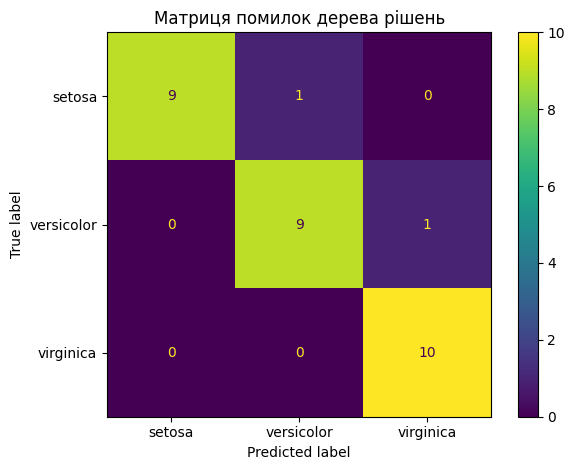

In [10]:
ConfusionMatrixDisplay.from_predictions(
    y_test, tree_test_predictions, labels=sorted(y.unique())
)
plt.title('Матриця помилок дерева рішень')
plt.tight_layout()
plt.show()


# 11. Аналіз помилкових прогнозів
Перевіряємо об’єкти, для яких прогноз не збігся зі справжнім класом.

In [11]:
test_results = X_test.copy()
test_results['actual'] = y_test.values
test_results['predicted'] = tree_test_predictions
test_results['correct'] = test_results['actual'] == test_results['predicted']
mistakes = test_results[~test_results['correct']]
print('Кількість помилкових прогнозів:', len(mistakes))
display(mistakes)
if len(mistakes):
    print('Найчастіше переплутані класи:')
    display(mistakes.groupby(['actual', 'predicted']).size().sort_values(ascending=False).rename('count'))
else:
    print('Помилок на цій тестовій вибірці немає.')


Кількість помилкових прогнозів: 2


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,measurement_device_device_a,measurement_device_device_b,measurement_device_device_c,actual,predicted,correct
10,5.4,3.7,4.3,0.2,1,0,0,setosa,versicolor,False
77,6.7,3.0,5.0,1.7,0,1,0,versicolor,virginica,False


Найчастіше переплутані класи:


,,count
actual,predicted,
setosa,versicolor,1
versicolor,virginica,1


# 12. Збереження моделі
Зберігаємо модель разом із назвами ознак і класів у форматі joblib.

In [12]:
model_bundle = {
    'model': tree_model,
    'feature_columns': X.columns.tolist(),
    'target_classes': sorted(y.unique().tolist())
}
joblib.dump(model_bundle, MODEL_PATH)
print('Модель збережено:', MODEL_PATH)


Модель збережено: /content/drive/MyDrive/pattern-recognition-practice/models/iris_decision_tree.joblib


# 13. Перевірка завантаженої моделі
Завантажуємо модель і перевіряємо прогноз одного об’єкта.

In [13]:
loaded_bundle = joblib.load(MODEL_PATH)
loaded_model = loaded_bundle['model']
print('Ознаки моделі:', loaded_bundle['feature_columns'])
print('Класи:', loaded_bundle['target_classes'])
one_object = X_test.iloc[[0]][loaded_bundle['feature_columns']]
loaded_prediction = loaded_model.predict(one_object)
print('Справжній клас:', y_test.iloc[0])
print('Прогноз моделі:', loaded_prediction[0])


Ознаки моделі: ['sepal_length_cm', 'sepal_width_cm', 'petal_length_cm', 'petal_width_cm', 'measurement_device_device_a', 'measurement_device_device_b', 'measurement_device_device_c']
Класи: ['setosa', 'versicolor', 'virginica']
Справжній клас: versicolor
Прогноз моделі: versicolor


# 14. Збереження таблиці метрик
Файл model_metrics.csv буде використано в README.md.

In [14]:
metrics_df.to_csv(METRICS_PATH, index=False)
print('Таблицю метрик збережено:', METRICS_PATH)


Таблицю метрик збережено: /content/drive/MyDrive/pattern-recognition-practice/reports/model_metrics.csv


# 15. Автоматична перевірка результатів
Контролюємо дані, кількість прогнозів, збереження моделі та перевагу дерева над базовою моделлю.

In [15]:
assert X_train.isna().sum().sum() == 0, 'У X_train залишилися пропуски.'
assert X_test.isna().sum().sum() == 0, 'У X_test залишилися пропуски.'
assert len(tree_test_predictions) == len(y_test), 'Кількість прогнозів неправильна.'
assert set(tree_test_predictions).issubset(set(y_train.unique()))
assert MODEL_PATH.exists(), 'Модель не збережено.'
assert METRICS_PATH.exists(), 'Таблиця метрик не збережена.'
assert tree_test_accuracy > dummy_test_accuracy, 'Дерево не перевищує базову модель.'
assert loaded_prediction[0] == tree_test_predictions[0], 'Прогнози моделі не збігаються.'
print('Усі основні перевірки виконано успішно.')


Усі основні перевірки виконано успішно.


# 16. Додаткове завдання
Порівнюємо дерево без обмеження глибини з деревом max_depth=3, щоб побачити можливі ознаки перенавчання.

In [16]:
deep_tree = DecisionTreeClassifier(max_depth=None, random_state=42)
deep_tree.fit(X_train, y_train)
deep_train_predictions = deep_tree.predict(X_train)
deep_test_predictions = deep_tree.predict(X_test)
deep_train_accuracy = accuracy_score(y_train, deep_train_predictions)
deep_test_accuracy = accuracy_score(y_test, deep_test_predictions)
print('Необмежене дерево, train accuracy:', round(deep_train_accuracy, 3))
print('Необмежене дерево, test accuracy:', round(deep_test_accuracy, 3))
print('Необмежене дерево, різниця:', round(deep_train_accuracy - deep_test_accuracy, 3))
print('Дерево max_depth=3, train accuracy:', round(tree_train_accuracy, 3))
print('Дерево max_depth=3, test accuracy:', round(tree_test_accuracy, 3))


Необмежене дерево, train accuracy: 1.0
Необмежене дерево, test accuracy: 0.9
Необмежене дерево, різниця: 0.1
Дерево max_depth=3, train accuracy: 0.983
Дерево max_depth=3, test accuracy: 0.933


# 17. Основні результати
Отримуємо числа, які потрібно вказати у висновках і README.md.

In [17]:
print('\nПІДСУМОК ДЛЯ ВИСНОВКІВ:')
print('Accuracy DummyClassifier (test):', round(dummy_test_accuracy, 3))
print('Accuracy DecisionTree (train):', round(tree_train_accuracy, 3))
print('Accuracy DecisionTree (test):', round(tree_test_accuracy, 3))
print('F1-macro DecisionTree (test):', round(f1_score(y_test, tree_test_predictions, average='macro'), 3))
print('Різниця accuracy train - test:', round(accuracy_gap, 3))
print('Кількість помилок:', len(mistakes))



ПІДСУМОК ДЛЯ ВИСНОВКІВ:
Accuracy DummyClassifier (test): 0.333
Accuracy DecisionTree (train): 0.983
Accuracy DecisionTree (test): 0.933
F1-macro DecisionTree (test): 0.933
Різниця accuracy train - test: 0.05
Кількість помилок: 2


# Висновки

Під час практичної роботи було побудовано дві моделі класифікації Iris: DummyClassifier та дерево рішень. Базова модель отримала accuracy 0.333, а дерево рішень 0.933 на тестовій вибірці.

Було розраховано основні метрики класифікації та побудовано матрицю помилок. Дерево правильно класифікувало 28 із 30 об'єктів. Різниця accuracy між навчальною та тестовою вибірками становила 0.05, що не свідчить про значне перенавчання.

У додатковому завданні було побудовано дерево без обмеження глибини та порівняно його з деревом глибини 3. Навчену основну модель і результати оцінювання збережено для подальшого використання.